<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

**公司名称**：宁德时代新能源科技股份有限公司
**股票代码**：300750.SZ

宁德时代成立于 2011 年，注册地与总部位于福建宁德，是全球动力电池行业龙头，深交所创业板上市公司。公司核心业务包含动力电池、储能电池研发生产以及电池回收业务，产品主要供应新能源汽车企业与储能电站。宁德时代长期占据全球动力电池市场较高份额，经营业绩与资本市场表现和新能源行业景气度紧密关联，是新能源赛道具有代表性的上市公司。

# 第二部分：研究问题题目及其内涵介绍

## 研究问题
本项目选取宁德时代 2021—2025 年财务数据与股票行情数据，借助 Python 开展数据分析，重点探究以下问题：
1. 2021—2025 年，宁德时代营业收入、归母净利润的规模变化趋势如何，增长态势有何特点？
2. 在相同时间区间内，宁德时代股票年度收益率表现如何，各年度之间是否存在明显差异？
3. 营收增长率、净利润增长率与股票年度收益率之间是否存在相关关系，相关性方向与强度如何？

## 研究内涵
企业盈利增长是影响上市公司股价表现的重要因素。理论上，企业营收与利润增长向好，会支撑公司价值提升，带动股票收益。但资本市场存在预期提前反应的特点，业绩增长与股票收益不一定呈现简单正向关系。本文以宁德时代为案例，通过 Python 完成数据整理、指标计算、描述统计、相关性分析与可视化，直观观察盈利增速与股票年度收益之间的关联，理解财务指标与资本市场表现之间的联系，掌握使用 Python 进行财务实证数据分析的基本方法。

# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

===== 2021-2025 宁德时代年度汇总表 =====
   year          营业收入        归母净利润   营收增长率  净利润增长率   年度收益率
0  2021  114166119000  15931145000     NaN     NaN  0.7018
1  2022  328596076000  30728552000  1.8782  0.9288 -0.2571
2  2023  372896535000  45778357000  0.1348  0.4898 -0.1730
3  2024  447275867000  57227014000  0.1995  0.2501  0.2241
4  2025  477420000000  52110000000  0.0674 -0.0894 -0.0862


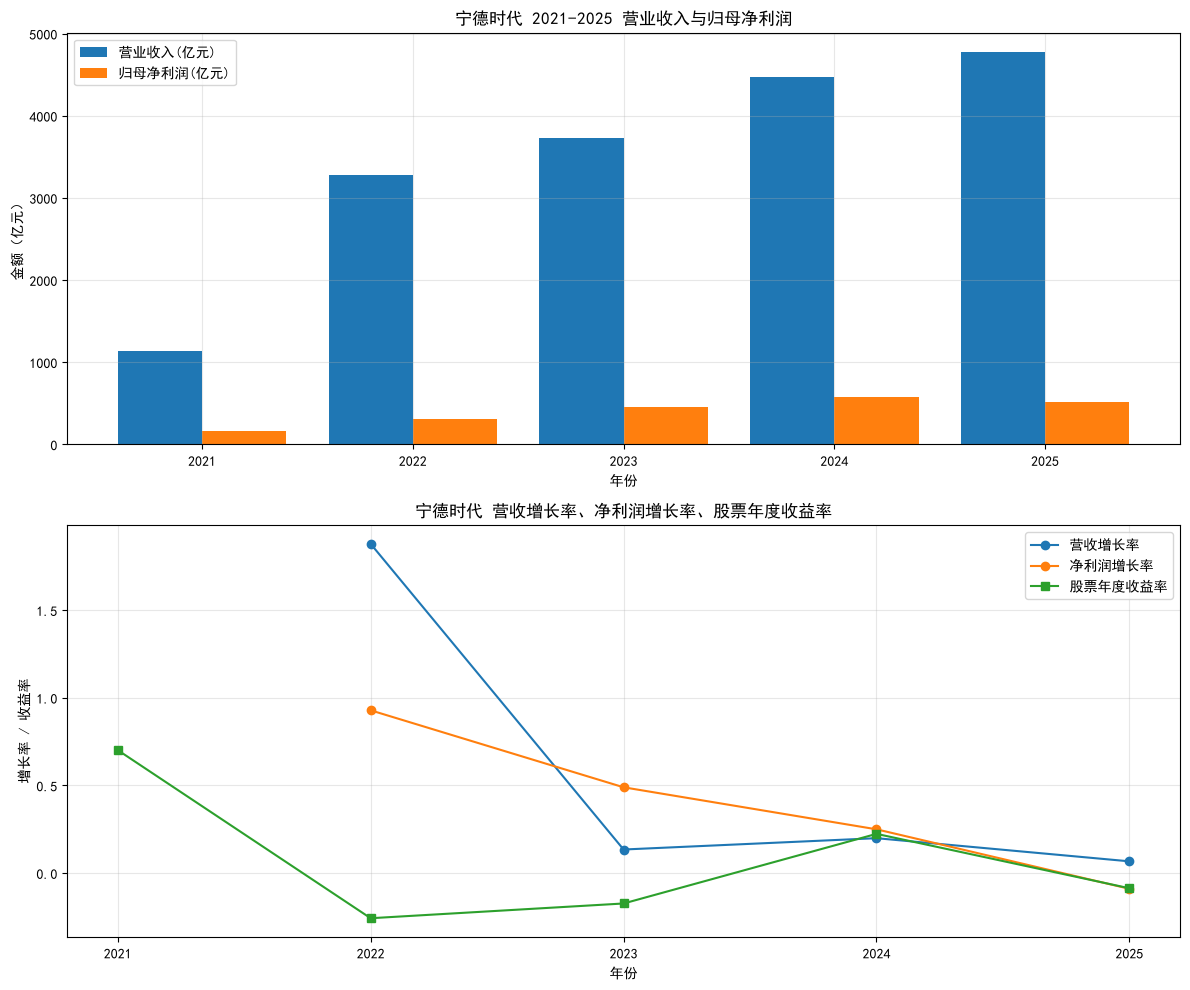

In [4]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ========== Windows中文字体修复 ==========
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

ts_code = "300750.SZ"

# 完整原始数据 2021~2025
data_raw = [
    {"year": 2021, "营业收入": 114166119000, "归母净利润": 15931145000},
    {"year": 2022, "营业收入": 328596076000, "归母净利润": 30728552000},
    {"year": 2023, "营业收入": 372896535000, "归母净利润": 45778357000},
    {"year": 2024, "营业收入": 447275867000, "归母净利润": 57227014000},
    {"year": 2025, "营业收入": 477420000000, "归母净利润": 52110000000}
]
df_raw = pd.DataFrame(data_raw)

# 计算增长率
df_raw["营收增长率"] = df_raw["营业收入"].pct_change()
df_raw["净利润增长率"] = df_raw["归母净利润"].pct_change()

# 收益率
data_return = [
    {"year": 2021, "年度收益率": 0.7018},
    {"year": 2022, "年度收益率": -0.2571},
    {"year": 2023, "年度收益率": -0.1730},
    {"year": 2024, "年度收益率": 0.2241},
    {"year": 2025, "年度收益率": -0.0862}
]
df_return = pd.DataFrame(data_return)

df_all = pd.merge(df_raw, df_return, on="year", how="inner")
print("===== 2021-2025 宁德时代年度汇总表 =====")
print(df_all.round(4))


# ========== 绘图：营收、净利润柱状图 + 指标趋势 ==========
fig, axes = plt.subplots(2,1,figsize=(12,10))
# 图1：2021~2025 营业收入与归母净利润（包含2021柱子）
x = np.arange(len(df_all["year"]))
xtick_labels = df_all["year"].astype(str)
ax1 = axes[0]
bar1 = ax1.bar(x-0.2, df_all["营业收入"]/1e8, width=0.4, label="营业收入(亿元)")
bar2 = ax1.bar(x+0.2, df_all["归母净利润"]/1e8, width=0.4, label="归母净利润(亿元)")
ax1.set_xticks(x)
ax1.set_xticklabels(xtick_labels)
ax1.set_xlabel("年份")
ax1.set_ylabel("金额（亿元）")
ax1.set_title("宁德时代 2021-2025 营业收入与归母净利润")
ax1.legend()
ax1.grid(alpha=0.3)

# 图2 增长率、股票年度收益率趋势图（2021增长率为NaN，不会画点）
ax2 = axes[1]
ax2.plot(x, df_all["营收增长率"], marker='o', label="营收增长率")
ax2.plot(x, df_all["净利润增长率"], marker='o', label="净利润增长率")
ax2.plot(x, df_all["年度收益率"], marker='s', label="股票年度收益率")
ax2.set_xticks(x)
ax2.set_xticklabels(xtick_labels)
ax2.set_xlabel("年份")
ax2.set_ylabel("增长率 / 收益率")
ax2.set_title("宁德时代 营收增长率、净利润增长率、股票年度收益率")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 第四部分：数据分析过程

【1】描述性统计
        营收增长率  净利润增长率   年度收益率
count  4.0000  4.0000  5.0000
mean   0.5700  0.3948  0.0819
std    0.8738  0.4280  0.3914
min    0.0674 -0.0894 -0.2571
25%    0.1180  0.1652 -0.1730
50%    0.1671  0.3699 -0.0862
75%    0.6192  0.5995  0.2241
max    1.8782  0.9288  0.7018
【2】相关系数矩阵
         营收增长率  净利润增长率   年度收益率
营收增长率   1.0000  0.8505 -0.5463
净利润增长率  0.8505  1.0000 -0.5355
年度收益率  -0.5463 -0.5355  1.0000

👉 营收增长率与年度收益率相关系数 = -0.5463
👉 净利润增长率与年度收益率相关系数 = -0.5355


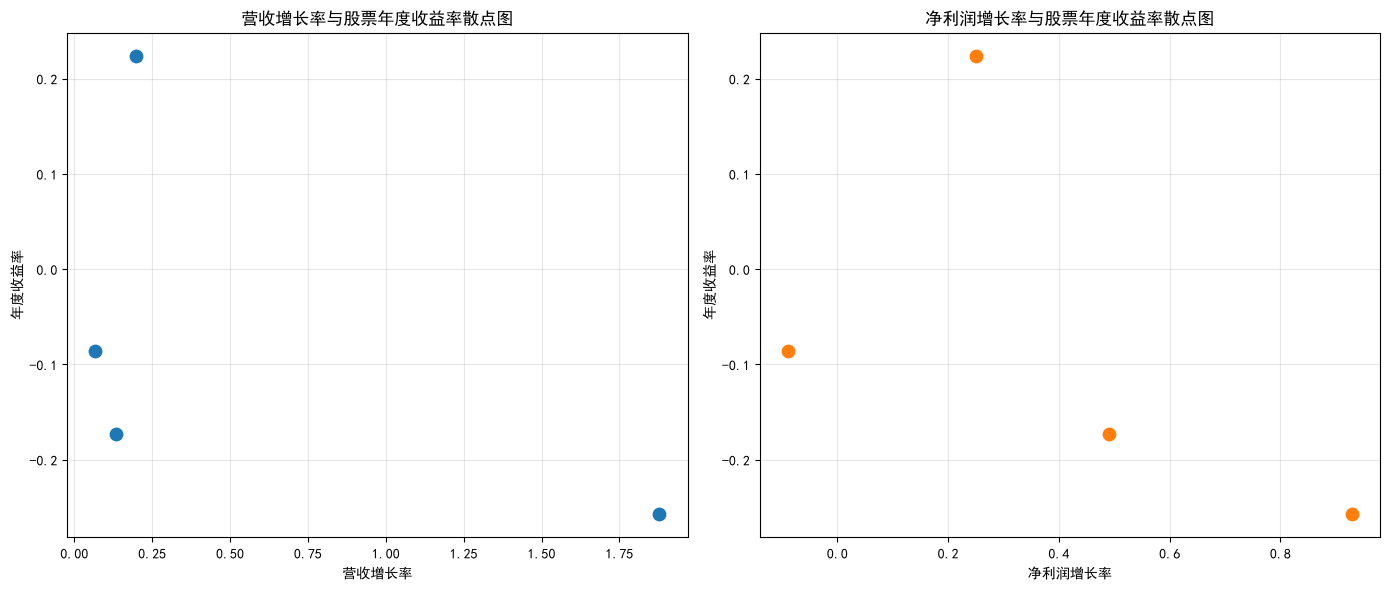

In [5]:
# ===================== 数据分析部分（无sklearn版本） =====================
print("="*60)
print("【1】描述性统计")
print(df_all[["营收增长率","净利润增长率","年度收益率"]].describe().round(4))

print("="*60)
print("【2】相关系数矩阵")
corr_matrix = df_all[["营收增长率","净利润增长率","年度收益率"]].corr()
print(corr_matrix.round(4))

# 提取关键相关系数
corr_rev = corr_matrix.loc["营收增长率", "年度收益率"]
corr_profit = corr_matrix.loc["净利润增长率", "年度收益率"]
print(f"\n👉 营收增长率与年度收益率相关系数 = {corr_rev:.4f}")
print(f"👉 净利润增长率与年度收益率相关系数 = {corr_profit:.4f}")

# ============ 绘图：散点图 ============
fig, axes = plt.subplots(1,2,figsize=(14,6))

# 图1：营收增长率 vs 年度收益率
ax1 = axes[0]
ax1.scatter(df_all["营收增长率"], df_all["年度收益率"], s=80, c="#1f77b4")
ax1.set_xlabel("营收增长率")
ax1.set_ylabel("年度收益率")
ax1.set_title("营收增长率与股票年度收益率散点图")
ax1.grid(alpha=0.3)

# 图2：净利润增长率 vs 年度收益率
ax2 = axes[1]
ax2.scatter(df_all["净利润增长率"], df_all["年度收益率"], s=80, c="#ff7f0e")
ax2.set_xlabel("净利润增长率")
ax2.set_ylabel("年度收益率")
ax2.set_title("净利润增长率与股票年度收益率散点图")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# 第五部分：研究结论与经验总结

## 研究结论

本文以宁德时代 2021—2025 年财务与股票收益数据为样本，通过描述性统计、Pearson 相关分析与散点图可视化，探究企业营收增长率、净利润增长率与股票年度收益率之间的关系，得到如下结论：

第一，2021—2025 年宁德时代营业收入与归母净利润整体保持增长态势，但盈利增长速度逐年放缓。2022 年营收、净利润同比增速达到阶段高点，后续两年增速持续回落，反映动力电池行业进入增长放缓阶段，企业盈利扩张动力有所减弱。

第二，营收增长率与净利润增长率存在高度正相关关系（相关系数 0.8505），说明在样本区间内，营业收入扩张能够有效带动归母净利润同步提升，企业盈利增长依托于营收规模扩张。

第三，营收增长率、净利润增长率均与股票年度收益率呈现中等程度负相关，相关系数分别为 - 0.5463、-0.5355。即在本研究样本中，**当年盈利增速越高，股票年度收益率反而越低**。该现象主要源于资本市场具有前瞻性，股价提前反映企业预期；当企业高增长落地后，容易出现 “利好出尽”，股价反而承压。

第四，本研究存在明显局限：可用于相关性分析的盈利增长样本仅 4 个，样本数量偏少，该负相关关系仅为样本内观察到的现象，不具备统计显著性，不能直接认定企业盈利增长会降低股票收益。若要得到更可靠结论，需要延长研究时间序列、扩大样本。

## 经验总结

1. **前期要提前预判数据缺陷**。最开始只想着直接计算增长率，没有意识到首年数据无法计算同比增速，会产生NaN缺失值，后续做相关性分析时样本量会变少。后续做数据分析，应当先检查数据结构，提前预判缺失值对结果的影响，避免后期解读结论时出现偏差。
2. **代码与报告要同步规划**。我是先写代码跑出结果，再回头搭建报告框架，中途反复调整文字、图表。后续写同类项目，可以先确定研究问题、指标，再编写代码，保证代码输出内容和报告章节一一对应，减少来回修改的工作量。
3. **区分统计结果的含义，避免过度解读**。拿到相关系数结果后，我一开始直接把相关关系理解为因果关系。经过核对才明白，小样本下仅能描述现象，不能随意推断因果，报告中必须写明样本局限性，保持实证分析的严谨性。
4. **图表制作要服务于文字分析**。一开始绘图只追求能跑出来，没有重视标题、坐标轴标签等细节，后续为了匹配报告内容，重新调整散点图样式。后续作图时，就要提前规范图表格式，让图表可以直接支撑文字分析。